In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Regularization in Regression
Regularization - modelin öyrənməsi zamanı modelin böyük koffisientlərinə (əmsallarlar) görə "cərimələr" tətbiq edərək (məhdudlaşdıraraq) overfiting-in qarşısını alır

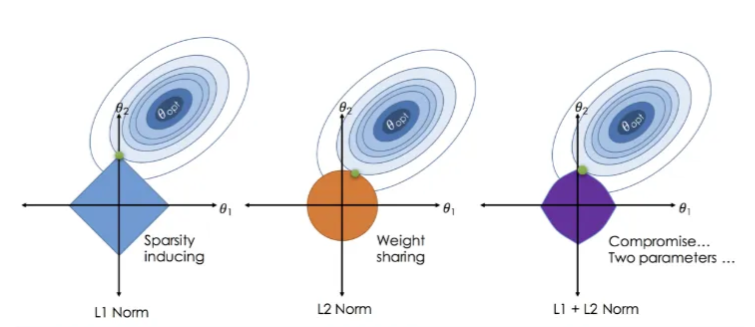

### Lasso Regression (L1 Regularization) - Least Absolute Shrinkage and Selection Operator

Cərimə: əmsalların mütləq qiymətlərinin cəmi

$$
L_{Lasso} = MSE + \lambda\sum_{j=1}^n{|w_j|}
$$

Təsiri:
- Bəzi əmsalları tam sıfıra endirə bilir
- Əlamətlərin avtomatik seçilməsi (Feature Selection) həyata keçirə bilir

### Ridge Regression (L2 Regularization)
Cərimə: əmsalların kvadratları cəmi

$$
L_{Ridge} = MSE + \lambda\sum_{j=1}^n{w_j^2}
$$

Təsiri:
- Bəzi əmsalların qiymətlərini kiçildir
- Adətən əmsalları sıfıra endirmir, yəni əlamətləri modeldən çıxarmır
- Modelin daha stabil olmasını təyin eləyir

### ElasticNet Regression (L1 + L2)

#### Hansı üsuldan nə vaxt istifadə edilir:

| Metod                | Nə zaman istifadə olunur                                                          |
|----------------------|-----------------------------------------------------------------------------------|
| Lasso (L1)           | Ən vacib əlamətləri seçmək və lazımsız əlamətləri modeldən çıxarmaq lazım olduqda |
| Ridge (L2)           | Əlamətlərin sayı çox olduqda və onların hamısını modeldə saxlamaq istədikdə       |
| ElasticNet (L1 + L2) | Əlamətlər arasında güclü korrlyasiya olduqda                                      |

In [2]:
np.random.seed(42)
n = 120

X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)

y = 0.5 * X[:,0] ** 3 - 3 * X[:, 0] ** 2 + 2 * X[:, 0] + noise

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [9]:
def train_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f'''{"="*10}{name}{"="*10}
        R2 Score: {r2_score(y_test, y_pred):.3f}
        RMSE:     {root_mean_squared_error(y_test, y_pred):.3f}
    ''')
    return model

In [11]:
degree = 10

ridge = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.)),
])

lasso = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=.05, max_iter=20000)),
])

elastic_net = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('elastic_net', ElasticNet(alpha=.05, max_iter=20000, l1_ratio=.3)),
])

ridge = train_model(ridge, 'Ridge')
lasso = train_model(lasso, 'Lasso')
elastic_net = train_model(elastic_net, 'ElasticNet')


==========Ridge==========
        R2 Score: 0.942
        RMSE:     6.121  
    
==========Lasso==========
        R2 Score: 0.948
        RMSE:     5.814  
    
==========ElasticNet==========
        R2 Score: 0.921
        RMSE:     7.160  
    


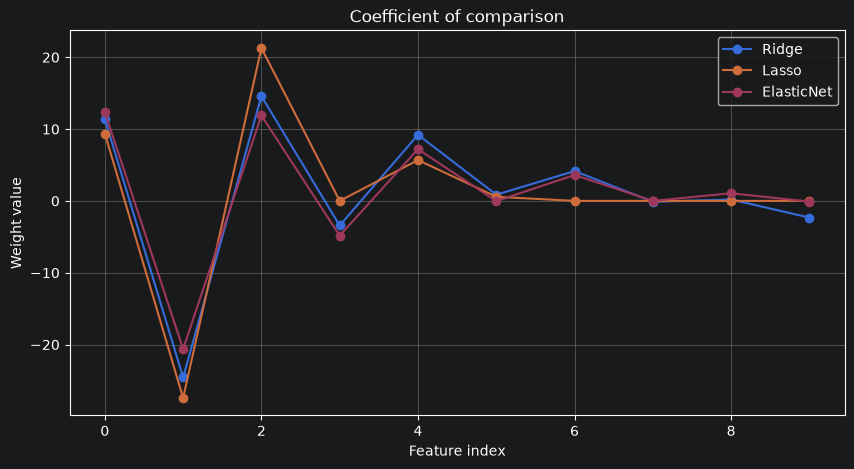

In [12]:
models = {
    'Ridge': ridge.named_steps['ridge'].coef_,
    'Lasso': lasso.named_steps['lasso'].coef_,
    'ElasticNet': elastic_net.named_steps['elastic_net'].coef_,
}

plt.figure(figsize=(10, 5))
for name, coef in models.items():
    plt.plot(coef, label=name, marker='o')

plt.title('Coefficient of comparison')
plt.xlabel('Feature index')
plt.ylabel('Weight value')
plt.legend()
plt.grid(True)
plt.show()